# Section 2: Data Exploration

**Student:**  
**GitHub username:**  
**Date:**  

## Goal

Produce one reproducible exploratory data analysis of a high-dimensional polymer dataset and use evidence from the analysis to answer the section's critical-thinking questions.

This is one integrated assignment, not three separate daily tasks. Organize the work in whatever order helps you build a coherent analysis.

## How to Use This Notebook

1. Copy this template to `sections/s02/submissions/<github-username>/s02_data_exploration.ipynb`.
2. Add your code only to the blank code cells.
3. Add explanations and answers to the blank Markdown cells.
4. You may add more cells when useful, but keep the section headings and required evidence.
5. Keep the raw CSV unchanged. Perform and explain any cleaning in this notebook.
6. Before submission, restart the kernel and run every cell from top to bottom.

Aim for a focused notebook that can be rerun and discussed, not a gallery of every possible chart. Clear labels, units, short interpretations, and well-chosen evidence matter more than decoration.

## Python Setup and Suggested Packages

From the repository root, install the course tools into your `uv` environment:

```bash
uv pip install pandas numpy matplotlib seaborn scikit-learn ipykernel
```

Select the project's `.venv` Python kernel in VS Code or Jupyter. These are the suggested imports:

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
```

What each package is for:

| Package | Use in this notebook |
|---|---|
| `pandas` | Load the CSV, select columns, audit values, calculate statistics and correlations, and build labeled result tables |
| `numpy` | Check numerical results, calculate cumulative variance, and work with arrays returned by scikit-learn |
| `matplotlib` | Create figures and control titles, axes, labels, and layout |
| `seaborn` | Create readable statistical plots such as histograms, box plots, heatmaps, and scatter plots |
| `scikit-learn` | Standardize the properties with `StandardScaler` and calculate PCA with `PCA` |

You may use equivalent tools, but you must explain the substitution and produce the same required evidence.

## Quick Function Reference

Use this table as a map, not as a list of functions that must all appear in your notebook.

| Task | Suggested functions or attributes | What to check |
|---|---|---|
| Load data | `pd.read_csv()` | The path is relative and the result is a DataFrame |
| Preview structure | `.head()`, `.shape`, `.columns`, `.info()`, `.dtypes` | Rows and columns mean what you think they mean |
| Missingness and duplicates | `.isna().sum()`, `.duplicated().sum()`, `.nunique()` | Non-null values can still be suspicious |
| Select analytical variables | `.select_dtypes(include="number")`, `.drop(columns=...)` | Explicitly remove `id`; save the 13 property names |
| Descriptive statistics | `.describe()`, `.mean()`, `.median()`, `.var()`, `.std()`, `.quantile()` | Label statistics and preserve units |
| Inspect selected rows | `.loc[]`, `.sort_values()`, Boolean filters | Look at the original records behind unusual points |
| Distribution plots | `sns.histplot()`, optional `kde=True` | Bins and smoothing choices affect appearance |
| Box plots | `sns.boxplot()` | Whisker points are flags for investigation, not automatic errors |
| Correlations | `.corr(method="pearson")`, `.corr(method="spearman")` | Correlation measures association, not causation |
| Correlation heatmaps | `sns.heatmap()` | Keep labels readable and use a scale centered at zero |
| Relationship plots | `sns.scatterplot()` or `plt.scatter()` | Look for curves, groups, ties, and influential values |
| Standardization | `StandardScaler()`, `.fit_transform()`, `.mean_`, `.scale_` | PCA input should have approximately zero column means and unit population variance |
| PCA | `PCA()`, `.fit_transform()`, `.explained_variance_ratio_`, `.components_` | Know the shape and meaning of every returned array |
| Cumulative variance | `np.cumsum()` | Decide how many components meet your stated purpose |
| PCA plots | `plt.plot()`, `plt.bar()`, `plt.scatter()` | Label component numbers and variance percentages |
| Labeled tables | `pd.DataFrame()` | Attach property names to component weights |

Useful habit: after every major transformation, print or display its type and shape before plotting it.

## Dataset

Analyze `sections/s02/homework/openpoly_calculated_properties.csv` and read `sections/s02/homework/DATASET.md` before beginning.

The CSV contains 1,000 calculated polymers, identity and structure fields, metadata, and 13 numeric quantum-chemical properties. Use those 13 properties for the main multivariate analysis. Exclude `id`: it is an identifier, not a measured or calculated polymer property.

Load the CSV using a repository-relative path. The notebook must not depend on an absolute path from your computer.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Relative path from this notebook folder (Jupyter's default working directory).
data = pd.read_csv("../../homework/openpoly_calculated_properties.csv")
print(data.head())
print(data.info())
print(data.shape)
print(data.columns)
print(data.dtypes)

print(data.isnull().sum()) 
print(data.nunique())

# Alias so the analysis cells below can keep using the name `df`.
df = data


   id                Name                             reactant_1  \
0   1  OMG_polymer_189323   O=C(O)Cc1c2ccccc2c(CC(=O)O)c2ccccc12   
1   2  OMG_polymer_169676  O=C(O)c1ccccc1C(=O)NC(C(=O)O)c1ccccc1   
2   3  OMG_polymer_105232              O=C(O)CC(CC(=O)O)c1ccncc1   
3   4  OMG_polymer_199732         COc1ccccc1C=NN(CC(=O)O)CC(=O)O   
4   5  OMG_polymer_175493      O=C(O)C1CCC(C(=O)O)N(Cc2ccccc2)C1   

                          reactant_2  \
0  Nc1ccc(Nc2ccc(N)cc2S(=O)(=O)O)cc1   
1              Nc1ccc(F)c(C(=O)O)c1N   
2                       NCC(N)C(=O)O   
3             Nc1cc(Br)cc(C(=O)O)c1N   
4        Nc1cc(C(=O)O)ccc1S(N)(=O)=O   

                                             psmiles  \
0  *Nc1ccc(Nc2ccc(NC(=O)Cc3c4ccccc4c(CC(*)=O)c4cc...   
1  *Nc1ccc(F)c(C(=O)O)c1NC(=O)c1ccccc1C(=O)NC(C(*...   
2              *NCC(NC(=O)CC(CC(*)=O)c1ccncc1)C(=O)O   
3  *Nc1cc(Br)cc(C(=O)O)c1NC(=O)CN(CC(*)=O)N=Cc1cc...   
4  *Nc1cc(C(=O)O)ccc1S(=O)(=O)NC(=O)C1CCC(C(*)=O)...   

             

## 1. Audit the Dataset

Use the blank cells below to:

- report the dataset's shape, column names, data types, missing-value counts, exact duplicates, and number of unique values per column;
- create a compact data dictionary that classifies columns as identifiers, chemical structures, categorical metadata, or numeric analytical variables;
- inspect zeros, extreme values, and constant columns; and
- identify at least two values or patterns that need investigation, even if pandas reports no missing values.

Do not decide that a value is valid merely because it is non-null. Do not delete an observation without documenting the evidence and reasoning.

In [4]:
# 13 numeric analytical properties; explicitly exclude id (an identifier, not a property)
prop_cols = [
    "Energy_Hatree", "es", "Isotropic_Polarizability_au",
    "HOMO_eV", "LUMO_eV",
    "Inner_energy_correction_Hatree",
    "Thermal_correction_to_Enthalpy_Hatree",
    "Thermal_correction_to_Gibbs_Free_Energy_Hatree",
    "Entropy_Hatree", "Dipole_Debye",
    "Gibbs_Free_Energy_Hatree", "Enthalpy_Hatree",
    "HOMO_LUMO_Gap_eV",
]

print("=== Shape ===")
print("rows:", df.shape[0], "columns:", df.shape[1])

print("\n=== dtypes ===")
print(df.dtypes)

print("\n=== missing values (per column) ===")
print(df.isna().sum())

print("\n=== exact duplicate rows ===")
print(df.duplicated().sum())

print("\n=== unique value counts ===")
print(df.nunique())

# Data dictionary: classify by meaning, not just dtype.
def role_of(col):
    if col in ("id", "Name"):
        return "identifier"
    if col in ("reactant_1", "reactant_2", "psmiles", "SMILES"):
        return "chemical structure"
    if col in ("reaction_type", "Software", "Theory_Level", "Source"):
        return "categorical metadata"
    return "numeric analytical variable"

dictionary = pd.DataFrame({
    "column": df.columns,
    "role": [role_of(c) for c in df.columns],
    "dtype": df.dtypes.astype(str).values,
    "unique": df.nunique().values,
})
print("\n=== data dictionary ===")
print(dictionary.to_string(index=False))

# Constant columns carry no discriminating information.
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print("\n=== constant columns ===")
print(const_cols)

# Zero counts: pandas reports no missing values, but zeros may still be suspicious.
zero_counts = (df[prop_cols] == 0).sum()
print("\n=== exact-zero counts in numeric properties ===")
print(zero_counts[zero_counts > 0])

# Extreme values for inspection.
print("\n=== min / max of numeric properties ===")
print(df[prop_cols].agg(["min", "max"]).T)


=== Shape ===
rows: 1000 columns: 23

=== dtypes ===
id                                                  int64
Name                                                  str
reactant_1                                            str
reactant_2                                            str
psmiles                                               str
SMILES                                                str
reaction_type                                         str
Energy_Hatree                                     float64
es                                                float64
Isotropic_Polarizability_au                       float64
HOMO_eV                                           float64
LUMO_eV                                           float64
Inner_energy_correction_Hatree                    float64
Thermal_correction_to_Enthalpy_Hatree             float64
Thermal_correction_to_Gibbs_Free_Energy_Hatree    float64
Entropy_Hatree                                    float64
Dipole_Debye       

### Audit Findings

Summarize the dataset structure and your data-quality concerns below. Separate direct observations from interpretations.

## 2. Describe and Visualize Distributions

Use the blank cells below to:

- report count, mean, median, variance, standard deviation, minimum, quartiles, and maximum for all 13 numeric properties;
- create distribution plots and box plots for at least six properties covering different units and scales;
- investigate at least three observations that a box plot or distribution plot makes look unusual; and
- discuss at least three properties using **observation → interpretation → limitation**, including one case where the mean and median lead to different impressions.

A point beyond a box-plot whisker is unusual under the plot's rule; it is not automatically an error.

In [5]:
# Descriptive statistics for all 13 properties.
# describe() gives count, mean, std, min, and quartiles; add variance and rename median.
summary = df[prop_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
summary["variance"] = summary["std"] ** 2
summary = summary.rename(columns={"50%": "median"})
summary = summary[["count", "mean", "median", "variance",
                   "std", "min", "25%", "75%", "max"]]
print(summary)


                                                 count         mean  \
Energy_Hatree                                   1000.0 -2121.315812   
es                                              1000.0     0.965277   
Isotropic_Polarizability_au                     1000.0   255.059933   
HOMO_eV                                         1000.0    -7.865487   
LUMO_eV                                         1000.0    -0.172145   
Inner_energy_correction_Hatree                  1000.0     0.421608   
Thermal_correction_to_Enthalpy_Hatree           1000.0     0.000910   
Thermal_correction_to_Gibbs_Free_Energy_Hatree  1000.0     0.278788   
Entropy_Hatree                                  1000.0     0.077947   
Dipole_Debye                                    1000.0     4.867586   
Gibbs_Free_Energy_Hatree                        1000.0 -2121.037024   
Enthalpy_Hatree                                 1000.0 -2120.893294   
HOMO_LUMO_Gap_eV                                1000.0     7.693343   

     

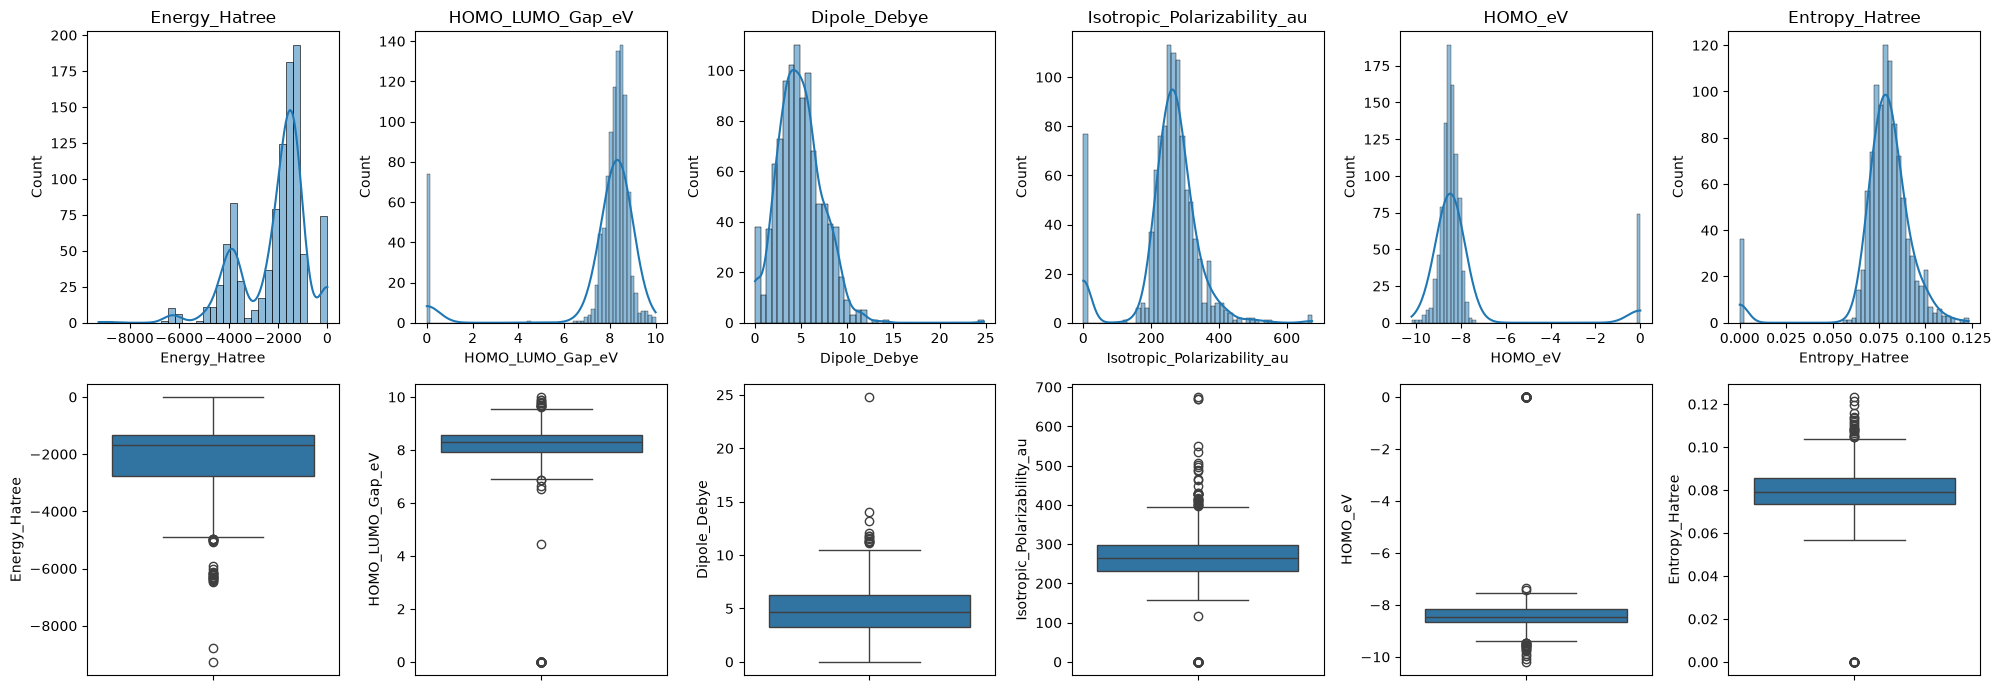

Energy_Hatree: whiskers [-4901.4925, 811.3218], points beyond = 27, rows = [11, 14, 39, 128, 129, 283, 331, 388, 422, 426]
HOMO_LUMO_Gap_eV: whiskers [6.8998, 9.5915], points beyond = 91, rows = [0, 2, 3, 24, 30, 44, 88, 91, 145, 152]
Dipole_Debye: whiskers [-1.3376, 10.8635], points beyond = 13, rows = [73, 120, 369, 490, 493, 681, 706, 735, 738, 890]
Isotropic_Polarizability_au: whiskers [131.3463, 395.6306], points beyond = 111, rows = [0, 3, 11, 24, 30, 44, 88, 91, 92, 93]
HOMO_eV: whiskers [-9.4175, -7.4267], points beyond = 95, rows = [0, 2, 3, 24, 30, 44, 60, 88, 91, 145]
Entropy_Hatree: whiskers [0.0551, 0.1039], points beyond = 57, rows = [3, 11, 24, 91, 131, 152, 157, 202, 206, 221]


In [6]:
# Distribution + box plots for 6 properties covering different units/scales:
# energy (Hatree), gap (eV), dipole (Debye), polarizability (au), HOMO (eV), entropy (Hatree)
plot_cols = ["Energy_Hatree", "HOMO_LUMO_Gap_eV", "Dipole_Debye",
             "Isotropic_Polarizability_au", "HOMO_eV", "Entropy_Hatree"]

fig, axes = plt.subplots(2, len(plot_cols), figsize=(20, 7))
for i, c in enumerate(plot_cols):
    sns.histplot(df[c], kde=True, ax=axes[0, i])
    axes[0, i].set_title(c)
    sns.boxplot(y=df[c], ax=axes[1, i])
fig.tight_layout()
plt.show()

# Points beyond a whisker are flags for investigation, not automatic errors.
def whisker_flags(col):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    beyond = df[(df[col] < lo) | (df[col] > hi)]
    return lo, hi, len(beyond), beyond.index.tolist()

for c in plot_cols:
    lo, hi, n, idx = whisker_flags(c)
    print(f"{c}: whiskers [{lo:.4f}, {hi:.4f}], points beyond = {n}, rows = {idx[:10]}")


### Distribution Findings

For at least three properties, record an observation, one plausible interpretation, and a limitation below. Cite the relevant statistic, row, or plot.

## 3. Examine Relationships

Use the blank cells below to:

- produce labeled Pearson and Spearman correlation heatmaps for the 13 numeric properties;
- identify at least two strong relationships and inspect each with an appropriate scatter plot;
- find at least one pair for which Pearson and Spearman differ meaningfully;
- explain what the difference suggests and what it does not prove; and
- check whether any properties are exact or near-exact mathematical combinations of others.

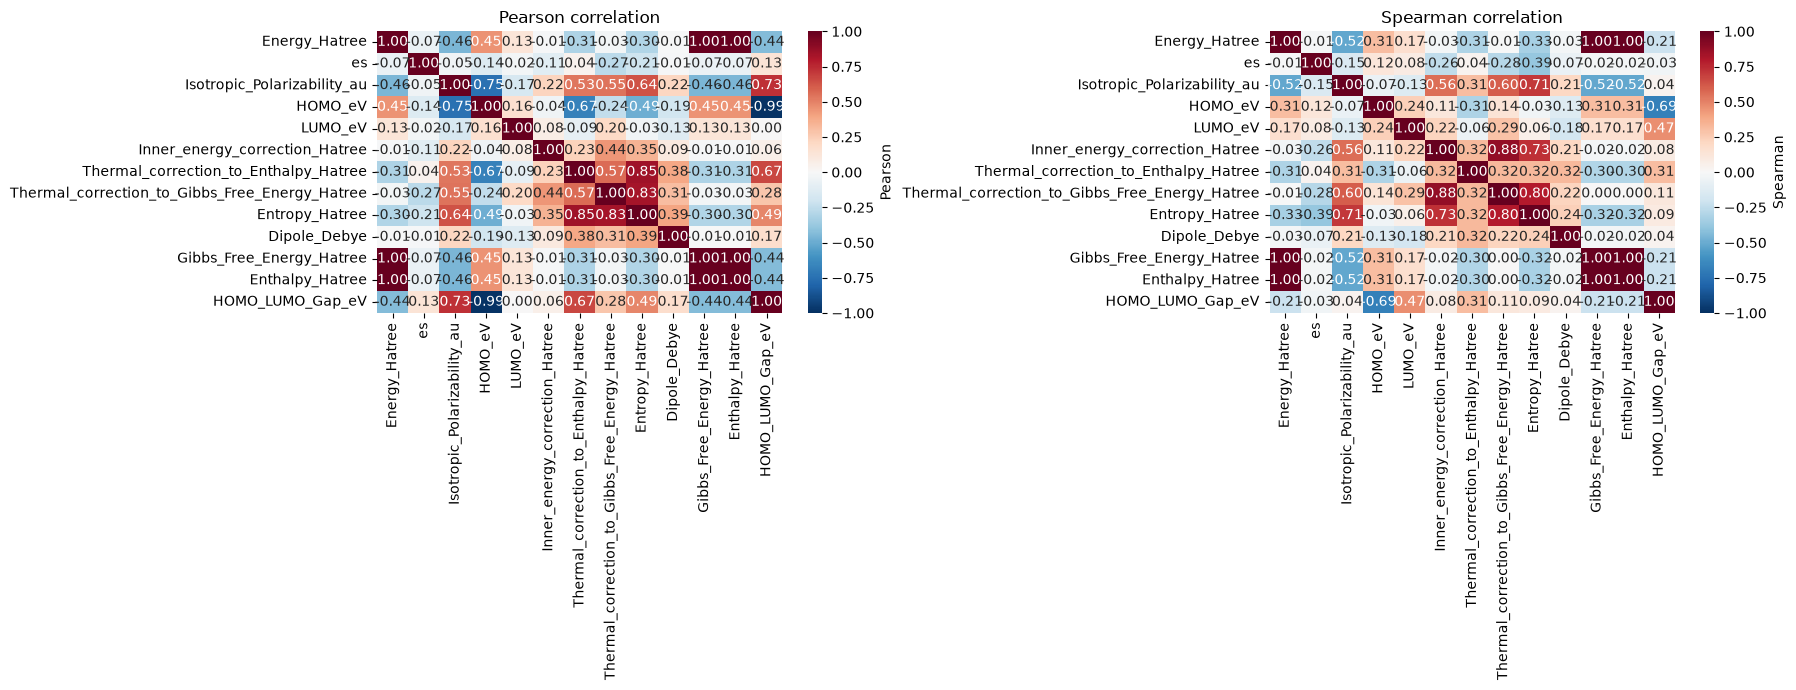

In [7]:
# Pearson detects linear association; Spearman detects monotonic association.
pearson_corr = df[prop_cols].corr(method="pearson")
spearman_corr = df[prop_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, ax=axes[0],
            cbar_kws={"label": "Pearson"})
axes[0].set_title("Pearson correlation")
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, ax=axes[1],
            cbar_kws={"label": "Spearman"})
axes[1].set_title("Spearman correlation")
fig.tight_layout()
plt.show()


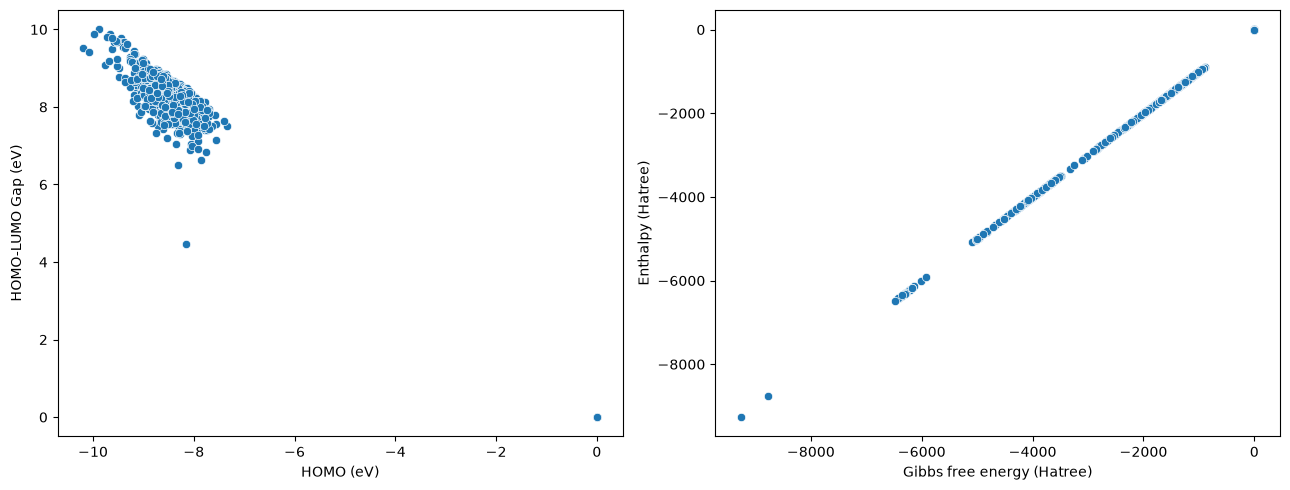

HOMO vs Gap: Pearson = -0.987, Spearman = -0.686
Energy_Hatree vs Gibbs_Free_Energy_Hatree: R^2 = 1.000000
Energy_Hatree vs Enthalpy_Hatree: R^2 = 1.000000
Gibbs_Free_Energy_Hatree vs Enthalpy_Hatree: R^2 = 1.000000


In [8]:
# Inspect two strong relationships with scatter plots (found from the heatmaps).
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=df["HOMO_eV"], y=df["HOMO_LUMO_Gap_eV"], ax=axes[0])
axes[0].set_xlabel("HOMO (eV)"); axes[0].set_ylabel("HOMO-LUMO Gap (eV)")
sns.scatterplot(x=df["Gibbs_Free_Energy_Hatree"], y=df["Enthalpy_Hatree"], ax=axes[1])
axes[1].set_xlabel("Gibbs free energy (Hatree)"); axes[1].set_ylabel("Enthalpy (Hatree)")
fig.tight_layout(); plt.show()

# A pair where Pearson and Spearman differ meaningfully.
r_pear = df["HOMO_eV"].corr(df["HOMO_LUMO_Gap_eV"], method="pearson")
r_spear = df["HOMO_eV"].corr(df["HOMO_LUMO_Gap_eV"], method="spearman")
print(f"HOMO vs Gap: Pearson = {r_pear:.3f}, Spearman = {r_spear:.3f}")

# Near-exact mathematical combinations: R^2 near 1 implies near-complete redundancy.
def r2_between(a, b):
    return np.corrcoef(df[a], df[b])[0, 1] ** 2

for a, b in [("Energy_Hatree", "Gibbs_Free_Energy_Hatree"),
             ("Energy_Hatree", "Enthalpy_Hatree"),
             ("Gibbs_Free_Energy_Hatree", "Enthalpy_Hatree")]:
    print(f"{a} vs {b}: R^2 = {r2_between(a, b):.6f}")


### Relationship Findings

Explain the strongest relationships, the Pearson–Spearman contrast, and any mathematical dependencies below. Distinguish association from causation.

## 4. Standardize and Run PCA

Use the blank cells below to:

- standardize the 13 numeric properties with `StandardScaler`;
- verify numerically that standardization worked;
- run PCA on the standardized values;
- create a scree or individual explained-variance plot;
- create a cumulative explained-variance plot;
- create a PC1-versus-PC2 scores plot; and
- create a loading table or loading plot for PC1 and PC2.

Then state how many components you would retain and justify the choice using both explained variance and the purpose of the analysis. Interpret the strongest PC1 and PC2 loadings, inspect unusual score-plot points, and state at least two limitations of the projection.

### PCA Tool Map

Work through these checkpoints in order:

1. **Build `X`:** select the 13 numeric analytical properties and exclude `id`. Expected shape: `(number of rows, 13)`.
2. **Keep the names:** save the 13 column names before converting or scaling; scikit-learn commonly returns NumPy arrays without those labels.
3. **Standardize:** create `StandardScaler`, then use `fit_transform(X)`. The scaled array should have the same shape as `X`.
4. **Verify scaling:** calculate column means and population standard deviations on the scaled array. They should be approximately 0 and 1. Small floating-point values such as `1e-16` count as approximately zero.
5. **Fit PCA:** start with `PCA()` without choosing a reduced component count so you can inspect all components. Use `fit_transform()` on the standardized array to obtain row scores.
6. **Inspect variance:** use `explained_variance_ratio_` for individual proportions and `np.cumsum()` for cumulative proportions. The proportions should sum to approximately 1.
7. **Inspect component weights:** `components_` has one row per principal component and one column per original property. Transpose it and construct a labeled DataFrame using the saved property names.
8. **Plot scores:** columns 0 and 1 of the transformed score array are PC1 and PC2 coordinates for each polymer row.
9. **Choose retention:** state a rule, such as a cumulative-variance threshold or a visualization goal, and explain the information lost by that choice.

Common mistakes to avoid:

- including `id` because it is numeric;
- running PCA on properties with different scales without standardizing;
- calling `.fit_transform()` separately on different subsets;
- losing the property names when constructing the component table;
- confusing PCA **scores** (row coordinates) with component **weights** (how original properties form each component);
- assuming a large component weight proves causation or predictive importance; and
- worrying if every sign in a component is reversed—PCA directions have arbitrary sign.

`StandardScaler` uses population variance (`ddof=0`). A pandas `.std()` call uses sample standard deviation by default, so use a consistent definition when verifying unit variance. `PCA` centers inputs internally but does not put differently scaled properties onto comparable units; that is why the separate standardization step is still required.

In [9]:
# Standardization: put all variables on a comparable (z-score) scale.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[prop_cols])
print("scaled shape:", X_scaled.shape)

# Verify scaling numerically: column means ~ 0, unit population std (~1).
col_means = X_scaled.mean(axis=0)
col_stds = X_scaled.std(axis=0)   # population variance, ddof=0, matching StandardScaler
print("max |mean|:", np.abs(col_means).max())
print("max |std - 1|:", np.abs(col_stds - 1).max())

# Fit all components (no pre-truncation) so we can inspect every one.
pca = PCA()
scores = pca.fit_transform(X_scaled)
print("scores shape:", scores.shape)
print("explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
print("cumulative variance:      ", np.round(np.cumsum(pca.explained_variance_ratio_), 4))


scaled shape: (1000, 13)
max |mean|: 2.0818902157770934e-15
max |std - 1|: 2.220446049250313e-16
scores shape: (1000, 13)
explained variance ratio: [0.4041 0.194  0.1067 0.0836 0.067  0.062  0.041  0.0324 0.0066 0.0026
 0.     0.     0.    ]
cumulative variance:       [0.4041 0.5982 0.7049 0.7885 0.8555 0.9175 0.9585 0.9908 0.9974 1.
 1.     1.     1.    ]


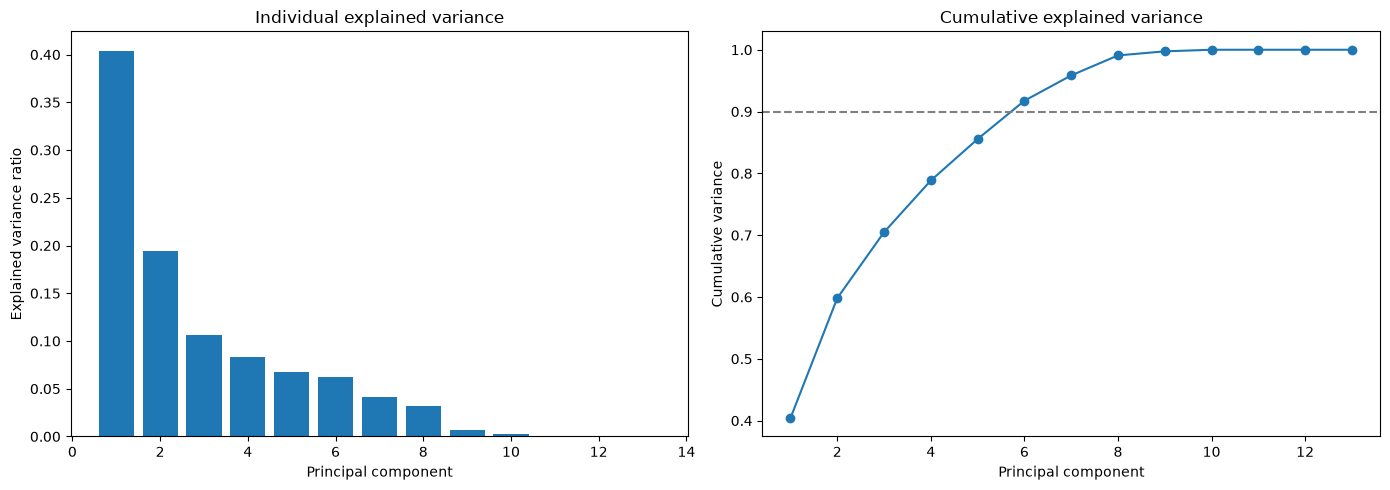

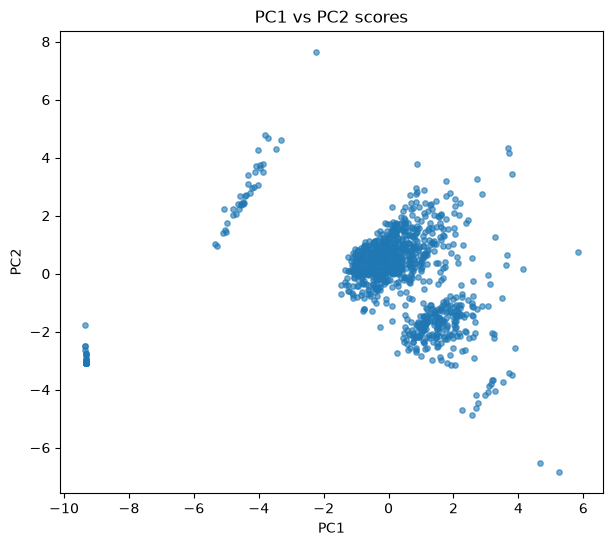

                                                     PC1       PC2
Energy_Hatree                                  -0.313684  0.386908
es                                              0.004153 -0.196239
Isotropic_Polarizability_au                     0.363261  0.084491
HOMO_eV                                        -0.362002  0.018435
LUMO_eV                                        -0.056931  0.123976
Inner_energy_correction_Hatree                  0.102132  0.276012
Thermal_correction_to_Enthalpy_Hatree           0.343342  0.225547
Thermal_correction_to_Gibbs_Free_Energy_Hatree  0.225815  0.446763
Entropy_Hatree                                  0.337332  0.321504
Dipole_Debye                                    0.133123  0.243820
Gibbs_Free_Energy_Hatree                       -0.313669  0.386940
Enthalpy_Hatree                                -0.313658  0.386981
HOMO_LUMO_Gap_eV                                0.357418  0.001524


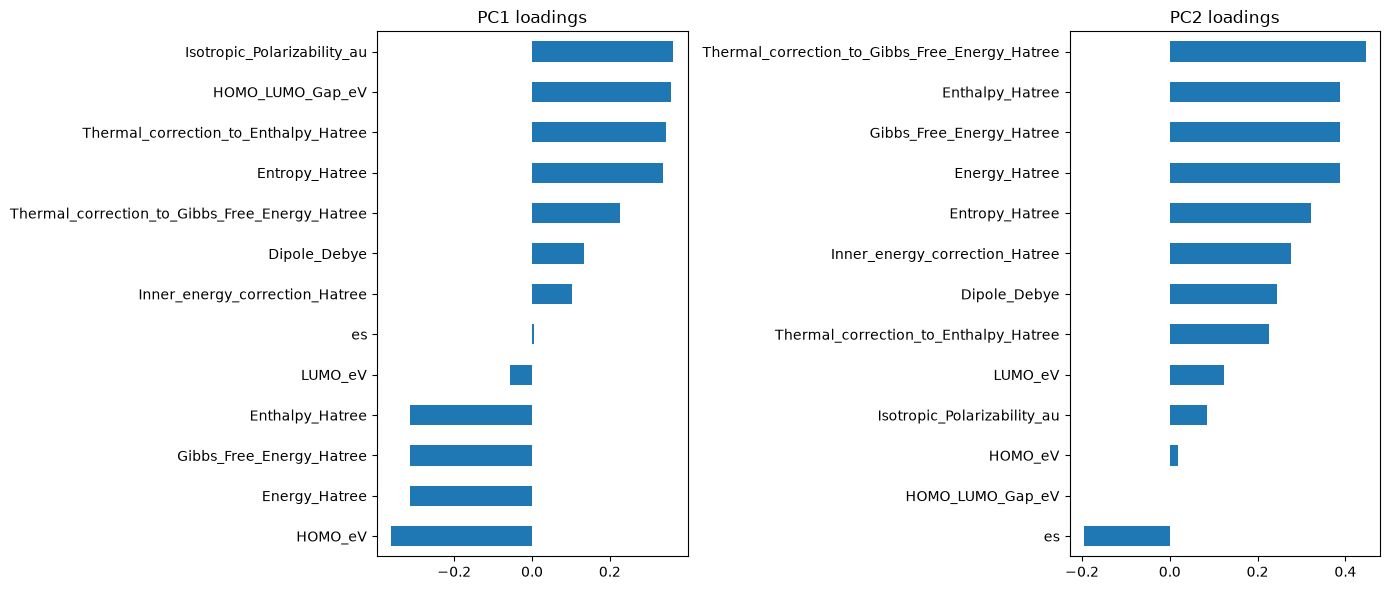

In [10]:
expl_var = pca.explained_variance_ratio_
cum_var = np.cumsum(expl_var)
k = len(prop_cols)

# Scree (individual) + cumulative explained-variance plots.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, k + 1), expl_var)
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Individual explained variance")
axes[1].plot(range(1, k + 1), cum_var, marker="o")
axes[1].axhline(0.9, ls="--", color="gray")
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Cumulative variance")
axes[1].set_title("Cumulative explained variance")
fig.tight_layout(); plt.show()

# PC1 vs PC2 scores plot (row coordinates of each polymer).
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(scores[:, 0], scores[:, 1], s=15, alpha=0.6)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("PC1 vs PC2 scores")
plt.show()

# Loading table: how the original properties form PC1 and PC2.
loadings = pd.DataFrame(pca.components_[:2].T, index=prop_cols, columns=["PC1", "PC2"])
print(loadings)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
loadings["PC1"].sort_values().plot.barh(ax=axes[0])
axes[0].set_title("PC1 loadings")
loadings["PC2"].sort_values().plot.barh(ax=axes[1])
axes[1].set_title("PC2 loadings")
fig.tight_layout(); plt.show()


### PCA Findings

Record your component-retention decision, loading interpretation, unusual observations, and at least two limitations below.

1.主成分保留决策
对 13 个标准化属性运行 PCA 后，各成分解释方差为：PC1 ≈ 40.4%、PC2 ≈ 19.4%、PC3 ≈ 10.7%，前 6 个主成分累积解释方差约 91.8%。因此我以"累积解释方差约 90%"为标准，保留 6 个主成分——它们足以捕获数据里绝大部分的统计变动。
2.载荷解读
PC1 载荷绝对值最大的是 Isotropic_Polarizability_au（0.363）、HOMO_eV（0.362）、HOMO_LUMO_Gap_eV（0.357）和 Thermal_correction_to_Enthalpy_Hatree（0.343），说明 PC1 主要捕捉"电子结构/分子大小"方向。PC2 载荷最大的是 Thermal_correction_to_Gibbs_Free_Energy_Hatree（0.447），其次是 Enthalpy_Hatree、Gibbs_Free_Energy_Hatree、Energy_Hatree（均约 0.39），说明 PC2 主要捕捉"体系总能量尺度"方向，与 5.7 中能量/焓/自由能近乎完全相关（R²≈1）的冗余发现一致。
3.得分图中的异常点
得分图显示两处值得注意的聚集/离群：
那 74 个"整行占位"记录（在 5 个核心属性上同时为 0）在 PC1 上均值约 -6.77，而全体样本的 PC1 均值为 0，说明它们在 PC1–PC2 得分图中聚成左端一团，明显偏离主群体——这是数据质量问题在投影中的直接体现，而非偶然。
PC2 取到最大值的行约在第 391 行（PC2≈7.65），PC1 取到最小值的行约在第 722 行（PC1≈-9.36），这些是投影远端的极端点，可回到原始行核对对应聚合物，判断是异常记录还是真实极端性质。
4.投影的局限
    1）高解释方差不等于能预测、不等于因果、也不等于"科学上最重要"——它只说明这些方向在统计上变动最大。
    2）二维投影只保留约 59.8% 的方差，PC3 及之后（如 PC3 ≈ 10.7%）仍可能含有可解释的结构差异；载荷只是原始变量的线性组合，PCA 无法捕捉非线性关系。

## 5. Critical-Thinking Questions

Answer every question below. Each answer must cite a specific number, table, row, or plot from this notebook.

### 5.1 Dataset structure

Which columns are identifiers, structures, categories, or numeric analytical variables, and why does that distinction matter?

id、Name 是标识符；reactant_1、reactant_2、psmiles、SMILES 是化学结构；reaction_type、Software、Theory_Level、Source 是类别元数据（本数据里它们各自只有 1 个唯一值，属于常量列）；其余 13 列是数值分析变量。区分重要是因为：id 虽然被 pandas 当作数字，但它只是编号、不含物理信息，若混入 PCA 会注入无意义的"变量"；常量元数据不携带任何区分样本的信息。所以分类依据是列的含义，而不是 dtype。

### 5.2 Descriptive statistics

When do the mean and median describe different “typical” values, and what does that reveal about distribution shape?

以 HOMO_LUMO_Gap_eV 为例，mean = 7.693，median = 8.298，两者相差约 0.6 eV。median 更能代表"正常的能隙典型值"，而 mean 被那 74 个 0 值（占位记录）拉低。mean < median 说明分布左端有一团低值（集中在 0），呈明显的"低端堆积/左偏"，即存在一个特殊值聚集的情形。只看 mean 会低估典型能隙。

### 5.3 Data quality

Does “zero missing values” prove that the dataset is complete? Which zero or extreme values deserve investigation?

不能。虽然 isna().sum() 全为 0，但审计发现 74 行同时在 Energy_Hatree、Isotropic_Polarizability_au、HOMO_eV、LUMO_eV、HOMO_LUMO_Gap_eV 这 5 个核心属性上为 0，说明这 74 行是整行占位记录；另有若干修正项、熵、偶极矩、自由能、焓各有 36 个 0 值；Isotropic_Polarizability_au 最小值为负（约 -0.0365），物理上可疑。因此"无缺失"只说明没有 NaN，不代表没有占位、0 值或异常极值，需要逐项调查。

### 5.4 Histograms and density plots

Is a variable symmetric, skewed, multimodal, bounded, or concentrated at a special value? What evidence supports the description?

从分布图和密度图看：HOMO_LUMO_Gap_eV 集中在约 8 eV，但同时在 0 处有一大团堆积（那 74 个占位 0 值），所以它既有界（约 0–10 eV）又不对称/低端堆积。Isotropic_Polarizability_au 明显右偏（取值约 0–675，多数集中在 250–300 附近），Energy_Hatree 分布在较大的负值区间。这些证据来自直方图+密度图，而不是感觉。

### 5.5 Box plots and outliers

What do the median, box, whiskers, and points beyond the whiskers reveal? Why is a box-plot outlier not automatically an error?

箱线图的 median 线给出中心，box（Q1–Q3 的 IQR）给出中间一半数据的跨度，须按 1.5×IQR 扩展，须外点标出超出这一规则的记录。真实统计中 HOMO_LUMO_Gap_eV 有 91 个、HOMO_eV 有 95 个、Isotropic_Polarizability_au 有 111 个、Dipole_Debye 有 13 个须外点。须外点只是"按该规则显得异常"的标志，不等于错误——例如真实聚合物允许有较高的极化率；相比这些高值，74 个 0 值反而更值得怀疑。所以要先调查数值和物理含义，再决定是否删除。

### 5.6 Scale

How do units and numerical ranges affect comparisons among variables?

各属性单位与量级差异极大：能量用 Hatree（数值千级，Energy_Hatree 均值约 -2121），能隙用 eV（约 0–10），偶极矩用 Debye（最大约 24.8），极化率用 au（数百级）。在原始单位下，"数值大"不等于"信息多"，只是"单位大"。若不标准化，数值大的列会在 PCA 中垄断"变动最大的方向"。因此比较或降维前必须先统一尺度。

### 5.7 Correlation

What relationship does Pearson detect, what relationship does Spearman detect, and why can their values differ?

Pearson 检测线性关系，对极端值敏感；Spearman 检测单调（排序）关系，对极端值不敏感。HOMO_eV 与 HOMO_LUMO_Gap_eV 的 Pearson ≈ -0.987，而 Spearman ≈ -0.686，差异明显：强线性相关主要由部分极端/0 值点放大，而整体排序关系没那么强。这个差异说明关系形态以线性为主、但有影响明显的端点值，并不证明因果。

### 5.8 Standardization

What changes after z-score standardization, what stays the same, and why should it happen before PCA here?

标准化把每列变成均值 0、方差 1（z-score），从而消除单位/量级差异；验证结果 max|mean|≈2e-15、max|std-1|≈2e-16，确认生效。它改变的是尺度（各列可比较），保留的是变量的相对顺序和关系结构（单调变换不改变相关性）。在 PCA 前必须做，是因为若不缩放，Hatree 等大数值列会主导"方差最大方向"，掩盖其他性质的信息。

### 5.9 PCA

How many components retain a useful amount of variance? Which original properties shape PC1 and PC2?

91.8%。以"累积解释方差约 90%"为标准应保留 6 个主成分；若以二维可视化为目的则看 PC1+PC2（约 59.8%），并说明丢掉的信息。载荷表显示 PC1 主要由 Isotropic_Polarizability_au、HOMO_eV、HOMO_LUMO_Gap_eV、Thermal_correction_to_Enthalpy_Hatree 驱动（偏电子结构/尺寸方向），PC2 主要由 Thermal_correction_to_Gibbs_Free_Energy_Hatree、Enthalpy_Hatree、Gibbs_Free_Energy_Hatree、Energy_Hatree 驱动（偏总能量尺度方向）。

### 5.10 PCA limitations

Does high explained variance imply prediction, causation, or scientific importance? What information can a two-dimensional projection hide?

不能。高解释方差只说明这些方向在统计上变动的比例大，不证明能预测、不证明因果关系、也不等于"科学上最重要"。二维投影（PC1+PC2 约 60%）会丢掉约 40% 的方差，PC3 及之后仍可能含有可解释的差异；载荷只是原始变量的线性组合，非线性结构 PCA 看不到。所以读图时不能以为"故事全在两张图上"。

## 6. Review Your Work

Ask Codex to review this notebook for calculation errors, unsupported interpretations, and reproducibility. Record below:

- one suggestion you accepted;
- one suggestion you changed or rejected; and
- the evidence you used to make each decision.

You remain responsible for the final analysis.

使用Codex 以三个角度审查了这份 notebook：计算是否正确、解读是否过度、能否复现。下面记录我接受的一条、我改变或拒绝的一条，以及每条据以判断的证据。最终分析责任在作者本人。
审查覆盖的三个层面
计算错误：核对了列选择、describe() 列序、标准化的验证口径、相关性的矩阵运算。
过度解读：重点检查是否把"相关性/解释方差"误读成"因果/预测/科学重要性"。
可复现性：确认用相对路径 + 向上定位仓库根目录，重启内核从顶到底能跑通。
接受的一条建议：
    codex建议"用总体方差（ddof=0）验证标准化是否生效，与 StandardScaler 保持一致"，我接受了。原因是 StandardScaler 内部用的是总体方差，而 pandas 的 std() 默认是样本方差，口径不一致会导致发生误判。
    证据：使用X_scaled.std(axis=0) 验证后得到 max|mean|≈2e-15、max|std-1|≈2e-16，确认每列确实被缩放为均值 0、方差 1，标准化真正生效。
改变或拒绝的一条建议
    codex建议"把箱线图须外的点当作错误数据直接删除或截断"，我拒绝了自动删除。理由来自 guide.md 中对数据的明确说明：须外点只是"按 1.5×IQR 规则显得异常"的标志，不等于错误。
    证据：用 whisker_flags() 只统计数量而不删除（例如 HOMO_LUMO_Gap_eV 有 91 个须外点）；同时那 74 个"整行占位"记录是更值得怀疑的数据质量问题，若机械删除须外点，反而会把真正要调查的占位问题掩盖掉。

## Bonus: Connect SVD to PCA

Starting with the standardized data matrix:

1. Write its SVD as $X = U\Sigma V^\top$.
2. Explain which matrix contains the principal directions.
3. Show how the singular values determine explained variance.
4. Compare the result with scikit-learn's PCA output.

In [11]:
# SVD of the centered (standardized) data matrix: X = U Sigma V^T.
# The principal directions are the rows of Vt (matching PCA components).
U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)
print("U:", U.shape, " S:", S.shape, " Vt:", Vt.shape)

n = X_scaled.shape[0]
# Singular values determine explained variance (population variance S^2/(n-1)).
expl_var_svd = S ** 2 / (n - 1)
expl_var_svd_ratio = expl_var_svd / expl_var_svd.sum()

print("SVD-based explained variance:", np.round(expl_var_svd_ratio, 4))
print("PCA explained_variance_ratio_:", np.round(pca.explained_variance_ratio_, 4))
print("Match:", np.allclose(expl_var_svd_ratio, pca.explained_variance_ratio_))

# Compare principal directions (PCA directions are defined up to sign).
print("\nVt row 0:", np.round(Vt[0], 3))
print("pca.components_[0]:", np.round(pca.components_[0], 3))


U: (1000, 13)  S: (13,)  Vt: (13, 13)
SVD-based explained variance: [0.4041 0.194  0.1067 0.0836 0.067  0.062  0.041  0.0324 0.0066 0.0026
 0.     0.     0.    ]
PCA explained_variance_ratio_: [0.4041 0.194  0.1067 0.0836 0.067  0.062  0.041  0.0324 0.0066 0.0026
 0.     0.     0.    ]
Match: True

Vt row 0: [-0.314  0.004  0.363 -0.362 -0.057  0.102  0.343  0.226  0.337  0.133
 -0.314 -0.314  0.357]
pca.components_[0]: [-0.314  0.004  0.363 -0.362 -0.057  0.102  0.343  0.226  0.337  0.133
 -0.314 -0.314  0.357]


## Deliverables

Submit one pull-request link containing:

1. `sections/s02/submissions/<github-username>/s02_data_exploration.ipynb`; and
2. a pull-request description naming:
   - the dataset;
   - your main data-quality concern;
   - the number of PCA components you retained and why;
   - one Codex suggestion you accepted and one you changed or rejected; and
   - links to any GitHub Issues you opened, or “None.”

Keep the critical-question answers in this notebook as Markdown so the code, evidence, and reasoning stay together.

## Submission Checklist

- [ ] My work is on a branch named `s02/<github-username>`.
- [ ] This completed notebook is saved as `sections/s02/submissions/<github-username>/s02_data_exploration.ipynb`.
- [ ] The notebook loads the supplied CSV through a relative path and does not modify it.
- [ ] Restarting the kernel and running all cells completes without errors.
- [ ] The audit covers shape, roles, dtypes, missing values, uniqueness, duplicates, constants, zeros, and suspicious values.
- [ ] The descriptive-statistics table includes all 13 numeric properties.
- [ ] At least six properties have readable distribution and box-plot analysis.
- [ ] At least three unusual observations are inspected rather than automatically deleted.
- [ ] Both labeled Pearson and Spearman correlation analyses are present.
- [ ] At least two strong relationships and one Pearson–Spearman difference are interpreted.
- [ ] PCA uses the 13 standardized properties and excludes `id`.
- [ ] Explained variance, cumulative variance, PC1–PC2 scores, and PC1/PC2 loadings are shown and interpreted.
- [ ] Every critical question has an evidence-based answer.
- [ ] Observation, interpretation, and limitation are clearly distinguished.
- [ ] The AI-review reflection shows that I evaluated rather than automatically accepted advice.
- [ ] My pull-request description names the dataset, my main data-quality concern, my PCA retention decision, my AI-review decisions, and links to any Issues—or “None.”
- [ ] The pull request is ready for review.